<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/lstm_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
print("GPU:", tf.config.list_physical_devices("GPU"))

PROJECT_DIR = "/content/drive/MyDrive/SER_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad"]

# Pick which spectrograms to use: "scaled" (original) or "noscale" (kept loudness)
DATA_VERSION = "noscale"

if DATA_VERSION == "scaled":
    X = np.load(f"{PROJECT_DIR}/logmel_X.npy")
    stats = np.load(f"{PROJECT_DIR}/norm_stats.npz")
else:
    X = np.load(f"{PROJECT_DIR}/logmel_X_noscale.npy")
    stats = np.load(f"{PROJECT_DIR}/norm_stats_noscale.npz")
mean, std = stats["mean"], stats["std"]
data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")

def get_split(name):
    idx = np.where(data["split"] == name)[0]
    x = (X[idx].astype(np.float32) - mean[None, :, None]) / std[None, :, None]
    return x[..., None], data["label"].values[idx]

X_train, y_train = get_split("train")
X_val,   y_val   = get_split("val")
X_test,  y_test  = get_split("test")
X_rav,   y_rav   = get_split("ravdess_test")
print("Using:", DATA_VERSION, "|", X_train.shape, X_val.shape, X_test.shape, X_rav.shape)

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using: noscale | (5329, 128, 351, 1) (1065, 128, 351, 1) (1048, 128, 351, 1) (1056, 128, 351, 1)


In [ ]:
import keras
from tensorflow.keras import layers, models

@keras.saving.register_keras_serializable()
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask=15, time_mask=35, n_freq=2, n_time=2, **kw):
        super().__init__(**kw)
        self.freq_mask, self.time_mask = freq_mask, time_mask
        self.n_freq, self.n_time = n_freq, n_time

    def _mask(self, x, axis, max_w, n):
        size, batch = tf.shape(x)[axis], tf.shape(x)[0]
        idx = tf.range(size)[None, :]
        keep = tf.ones([batch, size], dtype=tf.bool)
        for _ in range(n):
            w = tf.random.uniform([batch, 1], 0, max_w + 1, dtype=tf.int32)
            s = tf.random.uniform([batch, 1], 0, size, dtype=tf.int32)
            keep &= ~((idx >= s) & (idx < s + w))
        keep = tf.cast(keep, x.dtype)
        return x * (keep[:, :, None, None] if axis == 1 else keep[:, None, :, None])

    def call(self, x, training=None):
        if not training:
            return x
        x = self._mask(x, 1, self.freq_mask, self.n_freq)
        return self._mask(x, 2, self.time_mask, self.n_time)

    def get_config(self):
        return {**super().get_config(), "freq_mask": self.freq_mask, "time_mask": self.time_mask,
                "n_freq": self.n_freq, "n_time": self.n_time}

inputs = layers.Input(shape=(128, 351, 1))
x = SpecAugment()(inputs)
x = layers.Permute((2, 1, 3))(x)
x = layers.Reshape((351, 128))(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
x = layers.Dropout(0.3)(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

lstm = models.Model(inputs, outputs, name="bilstm_specaug")
lstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
lstm.summary()

Model: "bilstm_specaug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spec_augment_1 (SpecAugment)    │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute_1 (Permute)             │ (None, 351, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 351, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 351, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 351, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 351, 256)       │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 658,950 (2.51 MB)

 Trainable params: 658,950 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import keras
from tensorflow.keras import layers, models

@keras.saving.register_keras_serializable()
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask=15, time_mask=35, n_freq=2, n_time=2, **kw):
        super().__init__(**kw)
        self.freq_mask, self.time_mask = freq_mask, time_mask
        self.n_freq, self.n_time = n_freq, n_time

    def _mask(self, x, axis, max_w, n):
        size, batch = tf.shape(x)[axis], tf.shape(x)[0]
        idx = tf.range(size)[None, :]
        keep = tf.ones([batch, size], dtype=tf.bool)
        for _ in range(n):
            w = tf.random.uniform([batch, 1], 0, max_w + 1, dtype=tf.int32)
            s = tf.random.uniform([batch, 1], 0, size, dtype=tf.int32)
            keep &= ~((idx >= s) & (idx < s + w))
        keep = tf.cast(keep, x.dtype)
        return x * (keep[:, :, None, None] if axis == 1 else keep[:, None, :, None])

    def call(self, x, training=None):
        if not training:
            return x
        x = self._mask(x, 1, self.freq_mask, self.n_freq)
        return self._mask(x, 2, self.time_mask, self.n_time)

    def get_config(self):
        return {**super().get_config(), "freq_mask": self.freq_mask, "time_mask": self.time_mask,
                "n_freq": self.n_freq, "n_time": self.n_time}

inputs = layers.Input(shape=(128, 351, 1))
x = SpecAugment()(inputs)
x = layers.Permute((2, 1, 3))(x)
x = layers.Reshape((351, 128))(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
x = layers.Dropout(0.3)(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

lstm = models.Model(inputs, outputs, name="bilstm_specaug")
lstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])
lstm.summary()

Model: "bilstm_specaug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spec_augment_2 (SpecAugment)    │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute_2 (Permute)             │ (None, 351, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 351, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 351, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 351, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 351, 256)       │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 658,950 (2.51 MB)

 Trainable params: 658,950 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/bilstm_specaug_{DATA_VERSION}_best.keras",
                                       monitor="val_accuracy", save_best_only=True),
]

history = lstm.fit(X_train, y_train,
                   validation_data=(X_val, y_val),
                   epochs=80, batch_size=32,
                   callbacks=callbacks)

Epoch 1/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - accuracy: 0.3590 - loss: 1.5298 - val_accuracy: 0.3465 - val_loss: 1.5783 - learning_rate: 0.0010
Epoch 2/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - accuracy: 0.4020 - loss: 1.4558 - val_accuracy: 0.3822 - val_loss: 1.5011 - learning_rate: 0.0010
Epoch 3/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.4241 - loss: 1.4252 - val_accuracy: 0.3831 - val_loss: 1.4899 - learning_rate: 0.0010
Epoch 4/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4406 - loss: 1.3962 - val_accuracy: 0.3812 - val_loss: 1.5000 - learning_rate: 0.0010
Epoch 5/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.4491 - loss: 1.3719 - val_accuracy: 0.4216 - val_loss: 1.4259 - learning_rate: 0.0010
Epoch 6/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.4639 - loss: 1.3554 - val_accuracy: 0.4047 - val_loss: 1.4726 - learning_rate: 0.0010
Epoch 7/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 21s 70ms/step - accuracy: 0.4725 - l

{'model': 'bilstm_specaug_noscale', 'best_epoch': 50, 'val_acc': 53.71, 'ravdess_acc': 33.43}


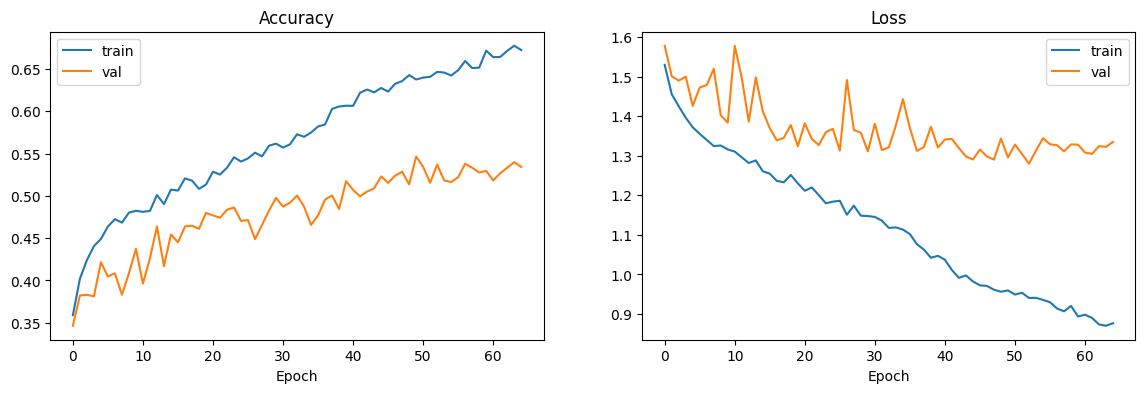

All saved to /content/drive/MyDrive/SER_Project


In [ ]:
import os, json
import pandas as pd
name = f"bilstm_specaug_{DATA_VERSION}"
LOG_DIR, FIG_DIR = f"{PROJECT_DIR}/logs", f"{PROJECT_DIR}/figures"
os.makedirs(LOG_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# 1. training history (score of every epoch)
pd.DataFrame(history.history).to_csv(f"{LOG_DIR}/{name}_history.csv", index_label="epoch")

# 2. final scores (model is already at its best epoch, 50)
val_acc = lstm.evaluate(X_val, y_val, verbose=0)[1]
rav_acc = lstm.evaluate(X_rav, y_rav, verbose=0)[1]
result = {"model": name, "best_epoch": 50,
          "val_acc": round(val_acc * 100, 2), "ravdess_acc": round(rav_acc * 100, 2)}
json.dump(result, open(f"{LOG_DIR}/{name}_result.json", "w"), indent=2)
print(result)

# 3. graph
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.savefig(f"{FIG_DIR}/{name}_curves.png", dpi=150)
plt.show()

# 4. model (checkpoint already saved the best one; this is a backup copy)
lstm.save(f"{MODEL_DIR}/{name}_final.keras")
print("All saved to", PROJECT_DIR)